# Retrievals: JAX Runtime Native Emission Tutorial

This notebook is a simple emission-spectrum retrieval built on the current runtime architecture.

It uses a built-in runtime-native emission model exported from `petitRADTRANS.retrieval.models`, rather than defining a custom model function in the notebook.

The notebook demonstrates:

- a built-in `runtime_native_*` emission model,
- `sampler_type="jaxns"`,
- runtime inspection before sampling,
- a compact emission setup that is easy to adapt.

## Before you start

This example uses the HR8799e GRAVITY spectrum distributed with the documentation example files.

To keep the notebook lightweight, it uses a clear-atmosphere Guillot-profile emission model with equilibrium chemistry and correlated-k opacities. The legacy emission tutorial remains the better reference for a full cloudy HR8799e setup.

In [1]:
import os
from pathlib import Path

os.environ.setdefault("OMP_NUM_THREADS", "1")
os.environ.setdefault("JAX_CHECK_TRACER_LEAKS", "False")

multinest_lib_dir = "/Users/nasedkin/software/MultiNest/lib/"
existing_dyld_path = os.environ.get("DYLD_LIBRARY_PATH", "")
if multinest_lib_dir not in existing_dyld_path.split(":"):
    os.environ["DYLD_LIBRARY_PATH"] = (
        f"{multinest_lib_dir}:{existing_dyld_path}"
        if existing_dyld_path else multinest_lib_dir
    )

import jax
import jax.numpy as jnp
import matplotlib.pyplot as plt
import tensorflow_probability.substrates.jax as tfp

from petitRADTRANS import physical_constants as cst
from petitRADTRANS.retrieval import Retrieval, RetrievalConfig
from petitRADTRANS.retrieval.models import guillot_emission

tfpd = tfp.distributions
jax.config.update("jax_enable_x64", True)

print(f"JAX devices: {jax.devices()}")

/Users/nasedkin/python-packages/jaxns/src/jaxns/internals/mixed_precision.py:14: UserWarning: JAX x64 is not enabled. Setting it now. Check for errors.
  warnings.warn("JAX x64 is not enabled. Setting it now. Check for errors.")


JAX devices: [CpuDevice(id=0)]


In [2]:
candidate_paths = [
    Path("retrievals/emission/observations/HR8799e_Spectra.fits"),
    Path("docs/content/notebooks/retrievals/emission/observations/HR8799e_Spectra.fits"),
]

for candidate in candidate_paths:
    if candidate.exists():
        example_data_file = candidate.resolve()
        break
else:
    raise FileNotFoundError(
        "Could not locate HR8799e_Spectra.fits. Try running the notebook from the repo root or from docs/content/notebooks."
    )

photometry_candidate_paths = [
    Path("retrievals/emission/observations/hr8799e_photometry.txt"),
    Path("docs/content/notebooks/retrievals/emission/observations/hr8799e_photometry.txt"),
]
photometry_data_file = next((path.resolve() for path in photometry_candidate_paths if path.exists()), None)

output_root = example_data_file.parents[4] / "runs" / "retrieval_jax_runtime_emission"
output_root.mkdir(parents=True, exist_ok=True)

pressures = jnp.logspace(-6.0, 2.0, 100)

print(f"Using emission spectrum file: {example_data_file}")
print(f"Photometry file available: {photometry_data_file is not None}")
print(f"Output directory: {output_root}")

Using emission spectrum file: /Users/nasedkin/python-packages/petitRADTRANS/docs/content/notebooks/retrievals/emission/observations/HR8799e_Spectra.fits
Photometry file available: True
Output directory: /Users/nasedkin/python-packages/petitRADTRANS/docs/content/runs/retrieval_jax_runtime_emission


## Retrieval configuration

This setup uses the built-in `guillot_emission` model directly. No notebook-defined wrapper is needed.

The physics is intentionally compact:

- a Guillot temperature profile,
- equilibrium chemistry via `Fe/H` and `C/O`,
- a small line list suitable for a first runtime-native emission example,
- one spectral dataset and no clouds.

In [ ]:
retrieval_config = RetrievalConfig(
    retrieval_name="hr8799e_runtime_native_emission_jaxns",
    run_mode="retrieval",
    sampler_type="jaxns",
    adaptive_mesh_refinement=False,
    scattering_in_emission=False,
    pressures=pressures,
)

retrieval_config.add_parameter(
    name="distance_to_system",
    is_free_parameter=False,
    value=41.2925 * cst.pc,
    plot_in_corner=False,
)

retrieval_config.add_parameter(
    name="log_g",
    is_free_parameter=True,
    distribution=tfpd.Uniform(low=3.0, high=5.0),
    plot_in_corner=True,
    corner_ranges=(3.0, 5.0),
    corner_label=r"$\log(g)$",
)
retrieval_config.add_parameter(
    name="planet_radius",
    is_free_parameter=True,
    distribution=tfpd.Uniform(low=0.8 * cst.r_jup, high=1.6 * cst.r_jup),
    plot_in_corner=True,
    corner_ranges=(0.8, 1.6),
    corner_label=r"R$_{pl}$",
    corner_transform=lambda radius: radius / cst.r_jup_mean,
)
retrieval_config.add_parameter(
    name="T_int",
    is_free_parameter=True,
    distribution=tfpd.Uniform(low=200.0, high=2000.0),
    plot_in_corner=True,
    corner_ranges=(200.0, 2000.0),
    corner_label=r"$T_{int}$",
)
retrieval_config.add_parameter(
    name="T_equ",
    is_free_parameter=True,
    distribution=tfpd.Uniform(low=600.0, high=2200.0),
    plot_in_corner=True,
    corner_ranges=(600.0, 2200.0),
    corner_label=r"$T_{eq}$",
)
retrieval_config.add_parameter(
    name="gamma",
    is_free_parameter=True,
    distribution=tfpd.Uniform(low=0.1, high=2.0),
    plot_in_corner=True,
    corner_ranges=(0.1, 2.0),
    corner_label=r"$\gamma$",
)
retrieval_config.add_parameter(
    name="log_kappa_IR",
    is_free_parameter=True,
    distribution=tfpd.Uniform(low=-5.0, high=0.0),
    plot_in_corner=True,
    corner_ranges=(-5.0, 0.0),
    corner_label=r"$\log \kappa_{IR}$",
)
retrieval_config.add_parameter(
    name="Fe/H",
    is_free_parameter=True,
    distribution=tfpd.Uniform(low=-1.0, high=1.5),
    plot_in_corner=True,
    corner_ranges=(-1.0, 1.5),
    corner_label=r"[Fe/H]",
)
retrieval_config.add_parameter(
    name="C/O",
    is_free_parameter=True,
    distribution=tfpd.Uniform(low=0.2, high=1.2),
    plot_in_corner=True,
    corner_ranges=(0.2, 1.2),
    corner_label=r"C/O",
)

retrieval_config.set_rayleigh_species(["H2", "He"])
retrieval_config.set_continuum_opacities(["H2--H2", "H2--He"])
retrieval_config.set_line_species(
    [
        "1H2-16O__POKAZATEL",
        "C-O-NatAbund__HITEMP",
    ],
    use_equilibrium_chemistry=True,
)

retrieval_config.add_data(
    name="GRAVITY",
    path_to_observations=str(example_data_file),
    model_generating_function=guillot_emission,
    data_resolution=500,
    model_resolution=300,
    wavelength_boundaries=(1.0, 2.5),
    line_opacity_mode="c-k",
)


gravity_data = retrieval_config.data["GRAVITY"]
print(f"Model function: {gravity_data.model_generating_function.__name__}")
print(f"Loaded points: {gravity_data.wavelengths.shape[0]}")
print(
    f"Wavelength range: {float(gravity_data.wavelengths.min()):.3f}--"
    f"{float(gravity_data.wavelengths.max()):.3f} micron"
    )

Model function: guillot_emission
Loaded points: 233
Wavelength range: 1.970--2.480 micron


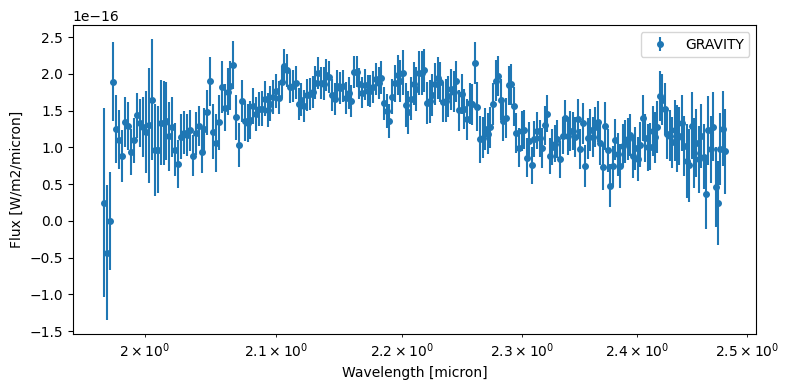

In [4]:
plt.figure(figsize=(8, 4))
plt.errorbar(
    gravity_data.wavelengths,
    gravity_data.spectrum,
    yerr=gravity_data.uncertainties,
    fmt='o',
    ms=4,
    label='GRAVITY',
    )
plt.xlabel('Wavelength [micron]')
plt.ylabel('Flux [W/m2/micron]')
plt.xscale('log')
plt.legend()
plt.tight_layout()

In [ ]:
retrieval = Retrieval(
    configuration=retrieval_config,
    output_directory=str(output_root),
    use_mpi=False,
    evaluate_sample_spectra=False,
    use_prt_plot_style=True,
    )

runtime = retrieval._get_runtime()
for group in runtime.model_groups:
    print({
        "source_name": group.source_name,
        "model_contract": group.model_contract,
        "observation_names": group.observation_names,
        "model_function": group.model_generating_function.__name__,
        })

# Set up plotting — these attributes live on the RetrievalPlotter after Retrieval is created
# Define axis properties of spectral plot if run_mode == 'evaluate'
retrieval.plotter.spec_xlabel = 'Wavelength [micron]'
retrieval.plotter.spec_ylabel = "Flux [W/m2/micron]"
retrieval.plotter.y_axis_scaling = 1.0
retrieval.plotter.xscale = 'log'
retrieval.plotter.yscale = 'linear'
retrieval.plotter.resolution = 100.0  # maximum resolution, will rebin the data
retrieval.plotter.nsample = 100  # if we want a plot with many sampled spectra

# Define from which observation object to take P-T in evaluation mode, add PT-envelope plotting options
retrieval.plotter.reference_data_name = 'GRAVITY'
retrieval.plotter.temp_limits = [150, 3000]
retrieval.plotter.press_limits = [1e2, 1e-5]

Setting up Radtrans object for data 'GRAVITY'...
Loading Radtrans opacities...


/opt/anaconda3/envs/jaxprt/lib/python3.12/site-packages/jax/_src/ops/scatter.py:104: FutureWarning: scatter inputs have incompatible types: cannot safely cast value from dtype=float64 to dtype=float32 with jax_numpy_dtype_promotion=standard. In future JAX releases this will result in an error.
  warnings.warn(
/opt/anaconda3/envs/jaxprt/lib/python3.12/site-packages/jax/_src/ops/scatter.py:104: FutureWarning: scatter inputs have incompatible types: cannot safely cast value from dtype=float64 to dtype=float32 with jax_numpy_dtype_promotion=standard. In future JAX releases this will result in an error.
  warnings.warn(
/opt/anaconda3/envs/jaxprt/lib/python3.12/site-packages/jax/_src/ops/scatter.py:104: FutureWarning: scatter inputs have incompatible types: cannot safely cast value from dtype=float64 to dtype=float32 with jax_numpy_dtype_promotion=standard. In future JAX releases this will result in an error.
  warnings.warn(
/opt/anaconda3/envs/jaxprt/lib/python3.12/site-packages/jax/_src

 Loading line opacities of species '1H2-16O__POKAZATEL.R300' from file '/Users/nasedkin/python-packages/petitRADTRANS/input_data/opacities/lines/correlated_k/H2O/1H2-16O/1H2-16O__POKAZATEL.R300_0.3-50mu.ktable.petitRADTRANS.h5'...

/opt/anaconda3/envs/jaxprt/lib/python3.12/site-packages/jax/_src/ops/scatter.py:104: FutureWarning: scatter inputs have incompatible types: cannot safely cast value from dtype=float64 to dtype=float32 with jax_numpy_dtype_promotion=standard. In future JAX releases this will result in an error.
  warnings.warn(


 Done.
 Loading line opacities of species 'C-O-NatAbund__HITEMP.R300' from file '/Users/nasedkin/python-packages/petitRADTRANS/input_data/opacities/lines/correlated_k/CO/C-O-NatAbund/C-O-NatAbund__HITEMP.R300_0.1-250mu.ktable.petitRADTRANS.h5'...

/opt/anaconda3/envs/jaxprt/lib/python3.12/site-packages/jax/_src/ops/scatter.py:104: FutureWarning: scatter inputs have incompatible types: cannot safely cast value from dtype=float64 to dtype=float32 with jax_numpy_dtype_promotion=standard. In future JAX releases this will result in an error.
  warnings.warn(
/opt/anaconda3/envs/jaxprt/lib/python3.12/site-packages/jax/_src/ops/scatter.py:104: FutureWarning: scatter inputs have incompatible types: cannot safely cast value from dtype=float64 to dtype=float32 with jax_numpy_dtype_promotion=standard. In future JAX releases this will result in an error.
  warnings.warn(
/opt/anaconda3/envs/jaxprt/lib/python3.12/site-packages/jax/_src/ops/scatter.py:104: FutureWarning: scatter inputs have incompatible types: cannot safely cast value from dtype=float64 to dtype=float32 with jax_numpy_dtype_promotion=standard. In future JAX releases this will result in an error.
  warnings.warn(
/opt/anaconda3/envs/jaxprt/lib/python3.12/site-packages/jax/_src

 Done.
 Successfully loaded all line opacities
 Loading CIA opacities for H2--H2 from file '/Users/nasedkin/python-packages/petitRADTRANS/input_data/opacities/continuum/collision_induced_absorptions/H2--H2/H2--H2-NatAbund/H2--H2-NatAbund__BoRi.R831_0.6-250mu.ciatable.petitRADTRANS.h5'... Done.
 Loading CIA opacities for H2--He from file '/Users/nasedkin/python-packages/petitRADTRANS/input_data/opacities/continuum/collision_induced_absorptions/H2--He/H2--He-NatAbund/H2--He-NatAbund__BoRi.DeltaWavenumber2_0.5-500mu.ciatable.petitRADTRANS.h5'... Done.
 Successfully loaded all CIA opacities
Successfully loaded all opacities
{'source_name': 'GRAVITY', 'model_contract': 'runtime_native', 'observation_names': ('GRAVITY',), 'model_function': 'guillot_emission'}


The runtime inspection above should show a single model group with `model_contract='runtime_native'` and the built-in `guillot_emission` function. That is what allows the retrieval to proceed through the JAXNS path without relying on a legacy adapter.

## Running JAXNS

Set `run_retrieval = True` to launch the nested sampler. The default stays `False` so that opening the notebook does not immediately start a retrieval.

The settings below are intentionally small for interactive testing. Increase them for science runs.

In [ ]:
run_retrieval = False

In [ ]:
if run_retrieval:
    retrieval.run(
        num_live_points=80,
        max_samples=60_000,
        s=4,
        k=0,
        c=200,
        shell_fraction=0.5,
        gradient_guided=False,
        init_efficiency_threshold=0.05,
        verbose=True,
        use_jit=True,
        seed=12345,
        )

In [ ]:
if run_retrieval:
    free_parameter_names = [
        name
        for name, parameter in retrieval.configuration.parameters.items()
        if parameter.is_free_parameter
        ]

    summary = retrieval.sampler.get_summary(free_parameter_names=free_parameter_names)
    print("Evidence:")
    print(summary.get("evidence", {}))
    print()
    print("Diagnostics:")
    print(summary.get("diagnostics", {}))
    print()
    print("Posterior summary:")
    posterior = summary.get("posterior", {})
    for name, stats in posterior.items():
        mean = stats.get("mean")
        std = stats.get("std")
        print(f"{name:>16s}: mean={mean}, std={std}")

    print()
    print("Saved JAXNS results:")
    print(output_root / "out_JAXNS" / f"{retrieval.configuration.retrieval_name}_jaxns_results.json")

## Notes

A few practical details are worth keeping in mind when adapting this tutorial:

- This notebook uses a built-in runtime-native model directly, so it exercises the current `models.py` runtime-native export surface rather than a notebook-local wrapper.
- The example intentionally omits clouds and photometry to keep the configuration simple. The legacy emission tutorial remains the better reference for a more realistic HR8799e science setup.
- A natural extension is to swap in another built-in native emission model, such as the spline-profile or Madhusudhan-Seager variants, and compare the change in parameterization.